# PROG8431 – Problem Analysis Workshop B
## K-Means Clustering with Ontario Residential Property Data

## Group 5 

### Team Members

| Name | Student ID |
|------|------------|
| Asangika Hettiarachchi | 7461502 |
| Juan Antonio Sainz Galvez | 9072844 |
| Ved 

**Dataset:** `properties(3).csv` (Ontario property listings)

### Workshop objective
Use unsupervised K-Means clustering to group properties with similar price and geographic characteristics. Clustering is an exploratory segmentation technique: the dataset has no known cluster labels, so the groups are interpreted rather than scored against a ground-truth answer.

### Workflow
1. Load and inspect the dataset.
2. Clean and prepare relevant features.
3. Scale the features because K-Means uses distance.
4. Explore candidate values of *k* with the elbow and silhouette methods.
5. Fit K-Means, visualize clusters, and interpret cluster profiles.

## 1. Imports and reproducibility

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

## 2. Load the data

In [5]:
# Place properties.csv in the same folder as this notebook.
properties = pd.read_csv("./data/properties.csv")

print("Shape:", properties.shape)
display(properties.head())

Shape: (25351, 6)


,Unnamed: 0,Address,AreaName,Price ($),lat,lng
0,0,"86 Waterford Dr Toronto, ON",Richview,999888,43.679882,-79.544266
1,1,"#80 - 100 BEDDOE DR Hamilton, ON",Chedoke Park B,399900,43.250000,-79.904396
2,2,"213 Bowman Street Hamilton, ON",Ainslie Wood East,479000,43.251690,-79.919357
3,3,"102 NEIL Avenue Hamilton, ON",Greenford,285900,43.227161,-79.767403
4,6,"#1409 - 230 King St Toronto, ON",Downtown,362000,43.651478,-79.368118


## 3. Inspect data quality and distributions

In [6]:
print(properties.info())
display(properties.describe(include="all").T)
print("\\nMissing values per column:")
display(properties.isna().sum())
print("\\nDuplicate rows:", properties.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 25351 entries, 0 to 25350
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  25351 non-null  int64  
 1   Address     25351 non-null  str    
 2   AreaName    24868 non-null  str    
 3   Price ($)   25351 non-null  int64  
 4   lat         25351 non-null  float64
 5   lng         25351 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 1.2 MB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,25351.0,NaN,NaN,NaN,42878.517613,31456.247046,0.0,19940.0,34037.0,61501.5,124929.0
Address,25351,23594,"223 Erb Street Waterloo, ON",16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AreaName,24868,1119,Downtown,830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price ($),25351.0,NaN,NaN,NaN,564543.765137,847596.167337,0.0,219900.0,371900.0,619900.0,32500000.0
lat,25351.0,NaN,NaN,NaN,37.326614,82.858347,-999.0,43.401087,43.715977,44.466711,53.851017
lng,25351.0,NaN,NaN,NaN,-85.218379,73.093572,-999.0,-80.308159,-79.503342,-79.107326,1.074519


\nMissing values per column:


Unnamed: 0      0
Address         0
AreaName      483
Price ($)       0
lat             0
lng             0
dtype: int64

\nDuplicate rows: 0


The file contains an index-like `Unnamed: 0` column, address and area text, property price, and latitude/longitude. `AreaName` has missing values; the clustering below does not require it. We retain price and coordinates, which are numeric and directly relevant to price/location segmentation.

## 4. Clean and select clustering features

In [7]:
# Remove the exported index column when present.
properties = properties.drop(columns=["Unnamed: 0"], errors="ignore")

# Ensure required fields are numeric and remove invalid/missing observations.
feature_columns = ["Price ($)", "lat", "lng"]
for col in feature_columns:
    properties[col] = pd.to_numeric(properties[col], errors="coerce")

clean = properties.dropna(subset=feature_columns).copy()
clean = clean[(clean["Price ($)"] > 0)]
clean = clean[clean["lat"].between(41, 57) & clean["lng"].between(-96, -74)]

print("Rows retained:", len(clean), "of", len(properties))
display(clean[feature_columns].describe())

Rows retained: 25014 of 25351


,Price ($),lat,lng
count,2.501400e+04,25014.000000,25014.000000
mean,5.689074e+05,43.953083,-79.391224
std,8.514445e+05,0.999087,1.984383
min,1.000000e+00,41.441582,-94.579636
25%,2.249000e+05,43.419636,-80.288904
50%,3.750000e+05,43.721115,-79.490196
75%,6.208500e+05,44.482428,-79.097587
max,3.250000e+07,51.253777,-74.415070


## 5. Explore the selected variables

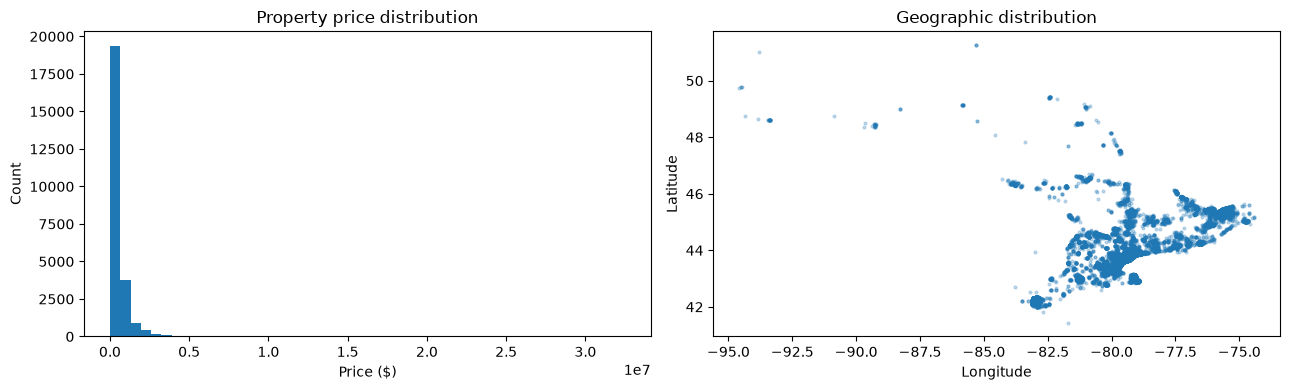

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(clean["Price ($)"], bins=50)
axes[0].set_title("Property price distribution")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")

axes[1].scatter(clean["lng"], clean["lat"], s=4, alpha=0.25)
axes[1].set_title("Geographic distribution")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
plt.tight_layout()
plt.show()

Prices are typically right-skewed, so use `log1p(price)` to reduce the influence of very expensive listings. Latitude and longitude remain in degrees. Standardization below gives each feature comparable scale before distance calculations.

## 6. Transform and standardize features

In [9]:
model_data = clean[["Price ($)", "lat", "lng"]].copy()
model_data["log_price"] = np.log1p(model_data["Price ($)"])

# Use log-price plus geographic coordinates for clustering.
model_features = model_data[["log_price", "lat", "lng"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(model_features)

print("Scaled feature means (approximately 0):", X_scaled.mean(axis=0).round(3))
print("Scaled feature standard deviations (approximately 1):", X_scaled.std(axis=0).round(3))

Scaled feature means (approximately 0): [0. 0. 0.]
Scaled feature standard deviations (approximately 1): [1. 1. 1.]


## 7. Choose a value of k: elbow and silhouette

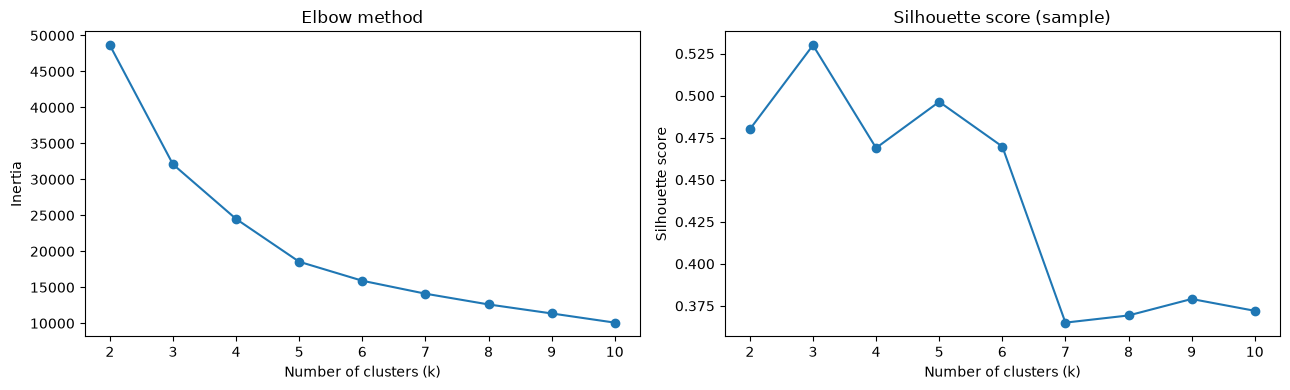

,k,inertia,silhouette
0,2,48650.934996,0.480011
1,3,32091.055578,0.529996
2,4,24501.266986,0.468906
3,5,18551.857444,0.496349
4,6,15910.522741,0.469750
5,7,14110.831021,0.365048
6,8,12616.099875,0.369311
7,9,11363.965740,0.379104
8,10,10088.146262,0.372076


In [10]:
# Sample for silhouette computation to keep runtime manageable.
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(5000, len(X_scaled))
sample_idx = rng.choice(len(X_scaled), size=sample_size, replace=False)
X_sample = X_scaled[sample_idx]

k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    # Fit on all rows for the elbow/inertia measure.
    km_full = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km_full.fit(X_scaled)
    inertias.append(km_full.inertia_)

    # Fit a separate model on the sample to estimate silhouette efficiently.
    km_sample = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    sample_labels = km_sample.fit_predict(X_sample)
    silhouette_scores.append(silhouette_score(X_sample, sample_labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette score (sample)")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(k_values), "inertia": inertias,
                      "silhouette": silhouette_scores}))

**How to decide:** the elbow plot shows where the reduction in inertia begins to slow. The silhouette score measures how well-separated clusters are (higher is generally better). Use both plots and interpretability; the best *k* is not determined by one metric alone.

## 8. Fit the final K-Means model

In [11]:
# Set this after reviewing the elbow and silhouette plots.
# The default k=4 is a starting point; change it if the plots support another value.
K = 4

kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10)
clean["Cluster"] = kmeans.fit_predict(X_scaled)

display(clean.groupby("Cluster").agg(
    Listings=("Price ($)", "size"),
    Median_Price=("Price ($)", "median"),
    Mean_Price=("Price ($)", "mean"),
    Median_Latitude=("lat", "median"),
    Median_Longitude=("lng", "median")
).round(2))

,Listings,Median_Price,Mean_Price,Median_Latitude,Median_Longitude
Cluster,,,,,
0,15182,469000.0,717401.41,43.67,-79.56
1,5789,298400.0,377266.41,45.34,-76.18
2,741,99.0,854.44,43.40,-80.26
3,3302,254900.0,349616.33,42.79,-82.36


## 9. Visualize the clusters

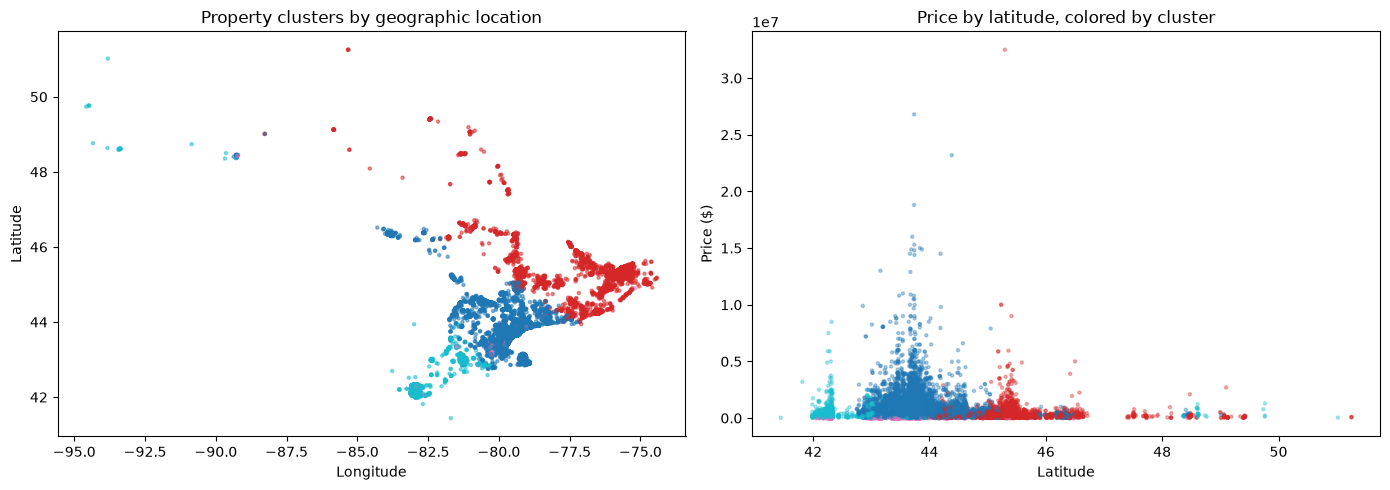

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

scatter = axes[0].scatter(
    clean["lng"], clean["lat"], c=clean["Cluster"],
    cmap="tab10", s=5, alpha=0.5
)
axes[0].set_title("Property clusters by geographic location")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

axes[1].scatter(
    clean["lat"], clean["Price ($)"], c=clean["Cluster"],
    cmap="tab10", s=5, alpha=0.35
)
axes[1].set_title("Price by latitude, colored by cluster")
axes[1].set_xlabel("Latitude")
axes[1].set_ylabel("Price ($)")
plt.tight_layout()
plt.show()

## 10. Interpret cluster profiles

In [13]:
cluster_profile = clean.groupby("Cluster").agg(
    Listing_Count=("Price ($)", "size"),
    Median_Price=("Price ($)", "median"),
    Mean_Price=("Price ($)", "mean"),
    Min_Price=("Price ($)", "min"),
    Max_Price=("Price ($)", "max"),
    Median_Latitude=("lat", "median"),
    Median_Longitude=("lng", "median")
).sort_values("Median_Price")

cluster_profile["Share_of_Listings_%"] = (
    100 * cluster_profile["Listing_Count"] / len(clean)
).round(2)

display(cluster_profile.round(2))

,Listing_Count,Median_Price,Mean_Price,Min_Price,Max_Price,Median_Latitude,Median_Longitude,Share_of_Listings_%
Cluster,,,,,,,,
2,741,99.0,854.44,1,7500,43.40,-80.26,2.96
3,3302,254900.0,349616.33,4000,8488000,42.79,-82.36,13.20
1,5789,298400.0,377266.41,1269,32500000,45.34,-76.18,23.14
0,15182,469000.0,717401.41,9000,26800000,43.67,-79.56,60.69


### Interpretation prompts
- Which cluster has the highest and lowest median property price?
- Do clusters appear geographically concentrated?
- Are some clusters mostly high-priced listings or broad geographic regions?
- Does the chosen *k* produce useful segments, or are some clusters difficult to distinguish?
- What are limitations of using only price and coordinates (e.g., property type, size, bedrooms, condition are not included)?

## 11. Conclusion

K-Means creates exploratory property segments using standardized log-price and geographic coordinates. The elbow and silhouette plots support selecting a practical number of clusters, while cluster summaries and maps help describe each segment. These clusters are not official market categories or causal explanations; they depend on the chosen features, scaling, and value of *k*.